# Day 94 — Introduction to Deep Learning

In this notebook we will:
1. See why a **linear model fails** on non-linear data and a **neural network succeeds**
2. Build a **single artificial neuron** from scratch (NumPy)
3. Build a tiny **multi-layer network (forward pass)** from scratch
4. Visualize **activation functions**
5. Prove why **non-linearity is needed**
6. Build the same network in **PyTorch** (optional) and count parameters

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split

np.random.seed(42)

## 1. Machine Learning vs Deep Learning on non-linear data

The *moons* dataset cannot be separated by a straight line.
Logistic Regression (classical ML, linear) vs a small neural network (MLP).

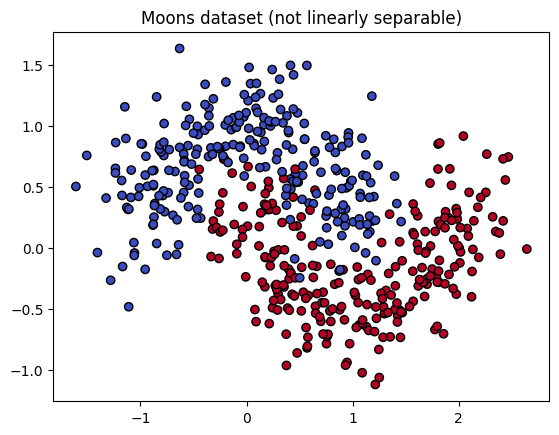

In [2]:
X, y = make_moons(n_samples=500, noise=0.25, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k")
plt.title("Moons dataset (not linearly separable)")
plt.show()

In [3]:
log_reg = LogisticRegression().fit(X_train, y_train)
mlp = MLPClassifier(hidden_layer_sizes=(16, 16), activation="relu",
                    max_iter=2000, random_state=42).fit(X_train, y_train)

print("Logistic Regression test accuracy:", round(log_reg.score(X_test, y_test), 3))
print("Neural Network (MLP) test accuracy:", round(mlp.score(X_test, y_test), 3))

Logistic Regression test accuracy: 0.85
Neural Network (MLP) test accuracy: 0.96


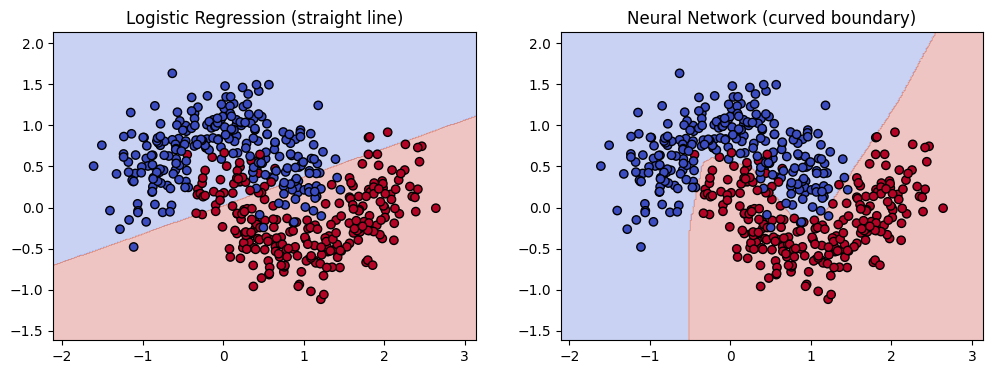

In [4]:
def plot_boundary(model, X, y, title, ax):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k")
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_boundary(log_reg, X, y, "Logistic Regression (straight line)", axes[0])
plot_boundary(mlp, X, y, "Neural Network (curved boundary)", axes[1])
plt.show()

**Observation:** the neural network learns a *curved* decision boundary on its own, with no manual feature engineering.

## 2. A single artificial neuron from scratch

`z = w · x + b`  →  `a = f(z)`

In [5]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def neuron(x, w, b, activation=sigmoid):
    z = np.dot(w, x) + b      # weighted sum + bias
    return activation(z)      # non-linearity

x = np.array([0.5, -1.2, 3.0])      # inputs
w = np.array([0.4, 0.7, -0.2])      # weights
b = 0.1                             # bias

print("z =", np.dot(w, x) + b)
print("a =", neuron(x, w, b))

z = -1.14
a = 0.24232036099629517


## 3. Activation functions

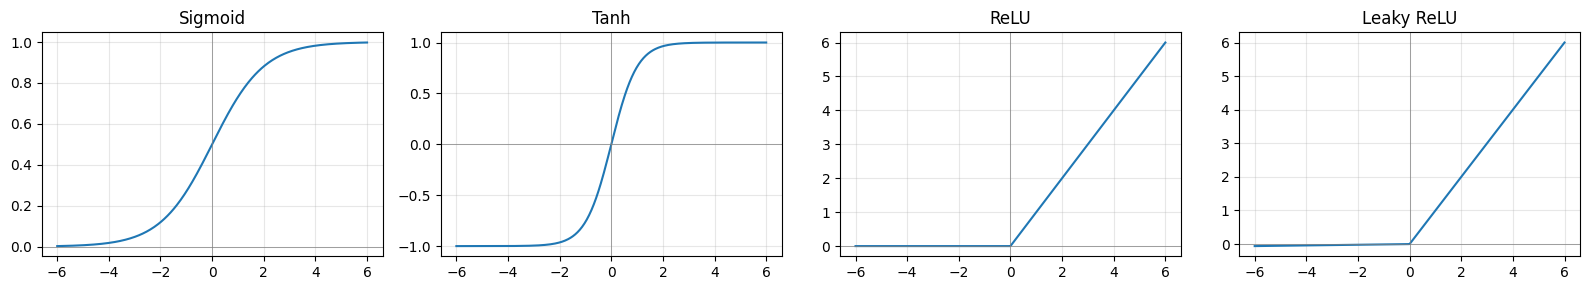

In [6]:
def relu(z):       return np.maximum(0, z)
def leaky_relu(z): return np.where(z > 0, z, 0.01 * z)
def tanh(z):       return np.tanh(z)

z = np.linspace(-6, 6, 400)
funcs = {"Sigmoid": sigmoid, "Tanh": tanh, "ReLU": relu, "Leaky ReLU": leaky_relu}

fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, (name, f) in zip(axes, funcs.items()):
    ax.plot(z, f(z))
    ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
    ax.set_title(name); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [7]:
def softmax(z):
    e = np.exp(z - np.max(z))   # subtract max for numerical stability
    return e / e.sum()

logits = np.array([2.0, 1.0, 0.1])
probs = softmax(logits)
print("Softmax:", probs, "| sum =", probs.sum())

Softmax: [0.65900114 0.24243297 0.09856589] | sum = 1.0


## 4. A tiny neural network (forward pass) from scratch

Architecture: **2 inputs → 4 hidden (ReLU) → 3 hidden (ReLU) → 1 output (Sigmoid)**

Weights are random here; *learning* them (backpropagation) comes in later days.

In [8]:
layer_sizes = [2, 4, 3, 1]

# initialise weights & biases
params = {}
for l in range(1, len(layer_sizes)):
    params[f"W{l}"] = np.random.randn(layer_sizes[l], layer_sizes[l-1]) * 0.5
    params[f"b{l}"] = np.zeros((layer_sizes[l], 1))
    print(f"W{l} shape: {params[f'W{l}'].shape}, b{l} shape: {params[f'b{l}'].shape}")

def forward(X, params):
    A = X.T                                  # shape: (features, samples)
    L = len(layer_sizes) - 1
    for l in range(1, L + 1):
        Z = params[f"W{l}"] @ A + params[f"b{l}"]
        A = sigmoid(Z) if l == L else relu(Z)   # sigmoid only on the output layer
    return A.T

preds = forward(X_test[:5], params)
print("\nPredictions (untrained, so basically random):\n", preds.ravel())

W1 shape: (4, 2), b1 shape: (4, 1)
W2 shape: (3, 4), b2 shape: (3, 1)
W3 shape: (1, 3), b3 shape: (1, 1)

Predictions (untrained, so basically random):
 [0.5        0.50614183 0.50209252 0.5        0.5       ]


In [9]:
total = sum(p.size for p in params.values())
print("Total trainable parameters:", total)
# check by hand: (2*4+4) + (4*3+3) + (3*1+1) = 12 + 15 + 4 = 31

Total trainable parameters: 31


## 5. Why non-linearity matters

Two stacked layers **without** activation collapse into one linear layer: `W2(W1 x) = (W2 W1) x`

In [10]:
W1 = np.random.randn(4, 2)
W2 = np.random.randn(1, 4)
x = np.random.randn(2, 1)

two_layers = W2 @ (W1 @ x)
one_layer  = (W2 @ W1) @ x

print("Two linear layers :", two_layers.ravel())
print("One combined layer:", one_layer.ravel())
print("Same result?      :", np.allclose(two_layers, one_layer))

Two linear layers : [3.82368398]
One combined layer: [3.82368398]
Same result?      : True


## 6. Same idea in PyTorch (optional)

Run `pip install torch` first if it is not installed. We will use PyTorch heavily from the next days.

In [11]:
try:
    import torch
    import torch.nn as nn

    model = nn.Sequential(
        nn.Linear(2, 4), nn.ReLU(),
        nn.Linear(4, 3), nn.ReLU(),
        nn.Linear(3, 1), nn.Sigmoid()
    )
    print(model)

    n_params = sum(p.numel() for p in model.parameters())
    print("Total trainable parameters:", n_params)   # should match 31

    out = model(torch.tensor(X_test[:5], dtype=torch.float32))
    print("Output:", out.detach().numpy().ravel())
except ImportError:
    print("PyTorch not installed. Run: pip install torch")

PyTorch not installed. Run: pip install torch


## Summary

- DL = neural networks with multiple layers that learn features automatically
- A neuron computes `a = f(w·x + b)`
- Non-linear activations make depth useful
- Forward pass = matrix multiplications + activations
- A linear model fails on non-linear data, an MLP handles it

## Practice exercises

1. Change `hidden_layer_sizes` in the MLP to `(2,)`, `(8,)`, `(32, 32)` and compare accuracy.
2. Try `make_circles` instead of `make_moons`. Does Logistic Regression do better?
3. Change the architecture in section 4 to `[2, 8, 8, 1]` and recompute the parameter count by hand and in code.
4. Replace ReLU with `tanh` in the forward pass and observe the output change.

*Next topic: Perceptron.*